# 02 — Does rain change how much NYC taxi passengers tip? (full year 2024)

**Research question.** Holding time, trip characteristics and temperature fixed, do passengers tip a different
share of the fare when it is raining at pickup?

**Why it is interesting.** Two opposite stories are plausible: passengers may tip *more* in the rain out of
gratitude (or because drivers are scarcer), or *less* because the trip is less pleasant and slower.

**What the pilot (notebook 01) left open.** With 30 days of April data the test could only detect large effects,
compared whole days, and did not control for confounders. This notebook:

1. uses all **12 months of 2024** (366 days, ~30 million card-paid trips);
2. validates the rain measure against a **ground-truth weather station** (NOAA, Central Park);
3. repeats the pilot's day-level test with ~12× more days, plus a power analysis;
4. measures rain **at the pickup hour** and estimates its effect with **regression** controlling for hour,
   day of week, month, holidays, temperature and trip characteristics, with standard errors clustered by day;
5. checks that the result is robust to the rain definition, outcome and sample.

**Data:** from the repository root run `python src/download_data.py` and then `python src/prepare_data.py`.

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.power import TTestIndPower

sns.set_theme(style="whitegrid", context="notebook")
FIG = "../figures/"
DATA = "../data/processed/"
SEED = 42
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

trips = pd.read_parquet(DATA + "trips_2024.parquet")
daily = pd.read_parquet(DATA + "daily_2024.parquet")
print(f"{len(trips):,} trips, {len(daily)} days")

29,393,010 trips, 366 days


## 1. Data and cleaning

Each step below keeps only rows that pass a rule. Card payments are required because TLC only records tips
paid by card, so cash trips would show a fake \$0 tip. Non-standard rate codes (negotiated, Newark, Nassau,
group rides) are dropped because their fares do not follow the meter. Tips above 100% of the fare are treated
as entry errors.

The outcome is the **tip rate**: tip as a percentage of the **pre-tip total** (fare + surcharges + tolls), the
amount shown on the payment screen and the base on which the preset tip buttons are computed. A rate is used
rather than the dollar tip because longer trips mechanically get larger dollar tips. (Section 3 shows why the
pre-tip total, not the fare alone, is the right base.)

In [2]:
log = pd.read_csv(DATA + "cleaning_log.csv")
log["rows"] = log.rows.map("{:,}".format)
log

,step,rows,share_of_raw
0,raw,"41,169,720",1.0000
1,pickup within month,"41,169,300",1.0000
2,credit card payment,"30,451,822",0.7397
3,standard or JFK rate,"29,560,221",0.7180
4,fare >= $3,"29,559,240",0.7180
5,0 < distance <= 100 mi,"29,447,075",0.7153
6,1 <= duration <= 180 min,"29,409,730",0.7144
7,0 <= tip <= 100% of pre-tip total,"29,393,010",0.7139


In [3]:
trips[["fare", "pre_tip_total", "tip", "tip_pct", "distance_mi", "duration_min", "temp_c", "precip_mm"]].describe().round(2)

,fare,pre_tip_total,tip,tip_pct,distance_mi,duration_min,temp_c,precip_mm
count,29393010.00,29393010.00,29393010.00,29393010.00,29393010.00,29393010.00,29393010.00,29393010.00
mean,18.78,24.42,4.29,17.81,3.25,16.30,14.04,0.16
std,15.67,17.72,3.66,6.96,4.19,12.84,9.66,0.80
min,3.00,4.50,0.00,0.00,0.01,1.00,-14.40,0.00
25%,9.30,14.00,2.24,15.00,1.04,7.78,6.40,0.00
50%,13.50,18.20,3.28,20.00,1.72,12.68,14.30,0.00
75%,21.20,25.90,4.98,20.00,3.16,20.50,22.20,0.00
max,420.00,421.00,150.00,100.00,99.58,179.93,35.50,16.10


## 2. Validating the rain measure

The hourly rain data come from Open-Meteo, which serves the **ERA5 reanalysis** (a gridded model estimate, not a
rain gauge). Before relying on it, compare its daily totals with the **NOAA Central Park weather station**.

Pearson r = 0.83, Spearman rho = 0.84
Agreement on rainy-day label (>= 1 mm): 88.8%
ERA5 rainy  False  True 
NOAA rainy              
False         234     27
True           14     91


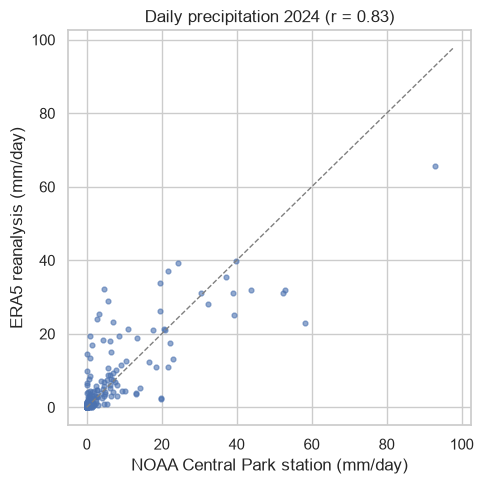

In [4]:
r_pearson = daily[["era5_prcp_mm", "noaa_prcp_mm"]].corr().iloc[0, 1]
r_spearman = stats.spearmanr(daily.era5_prcp_mm, daily.noaa_prcp_mm).statistic
agree = ((daily.era5_prcp_mm >= 1) == (daily.noaa_prcp_mm >= 1)).mean()
print(f"Pearson r = {r_pearson:.2f}, Spearman rho = {r_spearman:.2f}")
print(f"Agreement on rainy-day label (>= 1 mm): {agree:.1%}")
print(pd.crosstab(daily.noaa_prcp_mm >= 1, daily.era5_prcp_mm >= 1,
                  rownames=["NOAA rainy"], colnames=["ERA5 rainy"]))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(daily.noaa_prcp_mm, daily.era5_prcp_mm, s=12, alpha=0.6)
lim = max(daily.noaa_prcp_mm.max(), daily.era5_prcp_mm.max()) * 1.05
ax.plot([0, lim], [0, lim], color="grey", ls="--", lw=1)
ax.set(xlabel="NOAA Central Park station (mm/day)", ylabel="ERA5 reanalysis (mm/day)",
       title=f"Daily precipitation 2024 (r = {r_pearson:.2f})")
plt.tight_layout(); plt.savefig(FIG + "02_weather_validation.png", dpi=150); plt.show()

## 3. What tips look like

Measured against the pre-tip total, the tip distribution is dominated by sharp spikes at round percentages,
above all **exactly 20%**, the suggested amounts on the in-cab payment screen. Measured against the fare alone,
the same spikes are smeared out (right panel), which confirms that passengers react to the screen, not the fare.

Most passengers therefore press a preset button rather than choosing an amount. This matters for the research
question: if behaviour is anchored on a default, there is little room for weather to move tips.

Share of card trips with zero tip: 4.1%
Share of card trips tipping exactly 20% of the pre-tip total (to the cent): 46.4%


Mean tip: $4.29  |  mean tip rate: 17.8%  |  median tip rate: 20.0%
Most common tip rates among tippers (% of tippers): {20.0: 56.3, 25.0: 8.6, 15.0: 4.6, 10.0: 4.2, 30.0: 3.4, 19.0: 2.1}


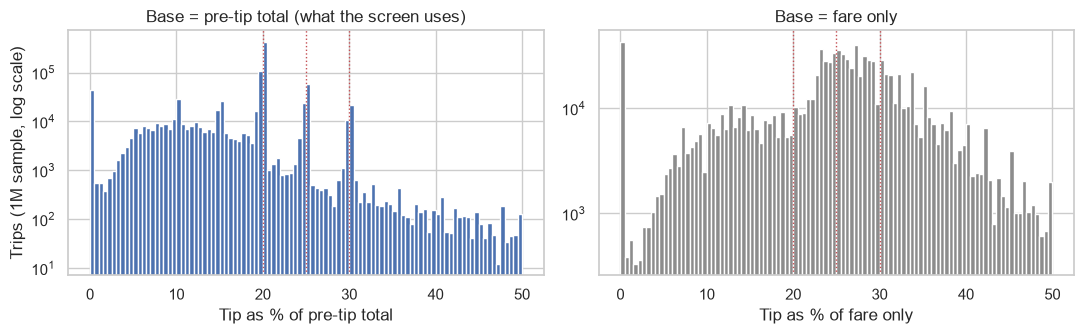

In [5]:
s = trips.sample(n=1_000_000, random_state=SEED)
print(f"Share of card trips with zero tip: {(~trips.tipped).mean():.1%}")
print(f"Share of card trips tipping exactly 20% of the pre-tip total (to the cent): {trips.tip_20.mean():.1%}")
print(f"Mean tip: ${trips.tip.mean():.2f}  |  mean tip rate: {trips.tip_pct.mean():.1f}%  "
      f"|  median tip rate: {trips.tip_pct.median():.1f}%")
top = (s.loc[s.tipped, "tip_pct"].round(0).value_counts(normalize=True).head(6) * 100).round(1)
print("Most common tip rates among tippers (% of tippers):", top.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.arange(0, 50.5, 0.5)
axes[0].hist(s.tip_pct, bins=bins, color="#4C72B0")
axes[0].set(xlabel="Tip as % of pre-tip total", ylabel="Trips (1M sample, log scale)", yscale="log",
            title="Base = pre-tip total (what the screen uses)")
axes[1].hist(s.tip_pct_fare, bins=bins, color="#8C8C8C")
axes[1].set(xlabel="Tip as % of fare only", title="Base = fare only", yscale="log")
for ax in axes:
    for x in (20, 25, 30):
        ax.axvline(x, color="#C44E52", ls=":", lw=1)
plt.tight_layout(); plt.savefig(FIG + "02_tip_pct_distribution.png", dpi=150); plt.show()

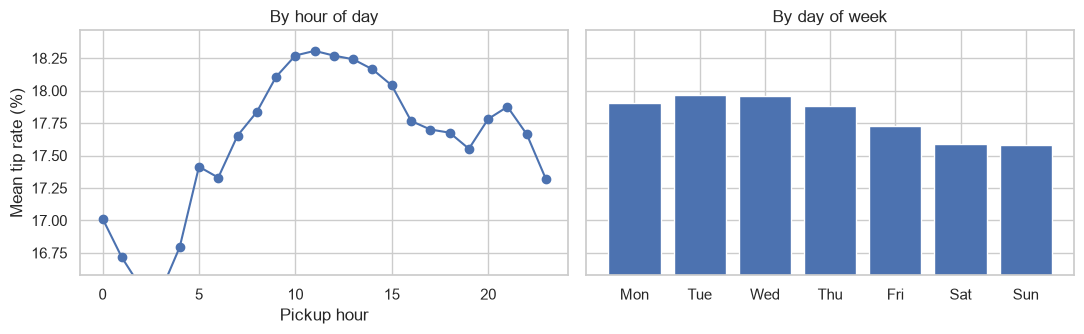

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
by_hour = trips.groupby("hour").tip_pct.mean()
by_dow = trips.groupby("dow").tip_pct.mean()
axes[0].plot(by_hour.index, by_hour.values, marker="o")
axes[0].set(xlabel="Pickup hour", ylabel="Mean tip rate (%)", title="By hour of day")
axes[1].bar(DOW, by_dow.values, color="#4C72B0")
axes[1].set(title="By day of week")
axes[1].set_ylim(by_dow.min() - 1, by_dow.max() + 0.5)
plt.tight_layout(); plt.savefig(FIG + "02_tip_by_time.png", dpi=150); plt.show()

Tipping varies systematically with time of day and day of week. If rainy hours are not spread evenly across
these times, a simple rainy-vs-dry comparison would mix up the effect of rain with the effect of *when* it rains.
This is why sections 5–6 use regression.

## 4. Replicating the pilot with the full year (day level)

Same design as notebook 01: one observation per day, a day is **rainy if the NOAA station records ≥ 1 mm**.

- H₀: μ_rainy = μ_dry  H₁: μ_rainy ≠ μ_dry  α = 0.05
- Outcomes: mean daily tip rate (% of pre-tip total) and mean daily tip (\$)

In [7]:
daily["rainy"] = daily.noaa_prcp_mm >= 1
rows = []
for col, label in [("mean_tip_pct", "Tip rate (%)"), ("mean_tip", "Tip ($)")]:
    rain, dry = daily.loc[daily.rainy, col], daily.loc[~daily.rainy, col]
    t, p = stats.ttest_ind(rain, dry, equal_var=False)
    p_mw = stats.mannwhitneyu(rain, dry).pvalue
    d = (rain.mean() - dry.mean()) / np.sqrt((rain.var() + dry.var()) / 2)
    rows.append({"outcome": label, "rainy days": len(rain), "dry days": len(dry),
                 "mean rainy": rain.mean(), "mean dry": dry.mean(), "diff": rain.mean() - dry.mean(),
                 "Welch t": t, "Welch p": p, "Mann-Whitney p": p_mw, "Cohen's d": d})
day_tests = pd.DataFrame(rows).round(3)
day_tests

,outcome,rainy days,dry days,mean rainy,mean dry,diff,Welch t,Welch p,Mann-Whitney p,Cohen's d
0,Tip rate (%),105,261,17.820999,17.792,0.029,0.979,0.329,0.241,0.116
1,Tip ($),105,261,4.233000,4.316,-0.083,-3.106,0.002,0.001,-0.365


Minimum detectable effect (80% power): pilot 15 vs 15 days d = 1.06; full year 105 vs 261 days d = 0.32


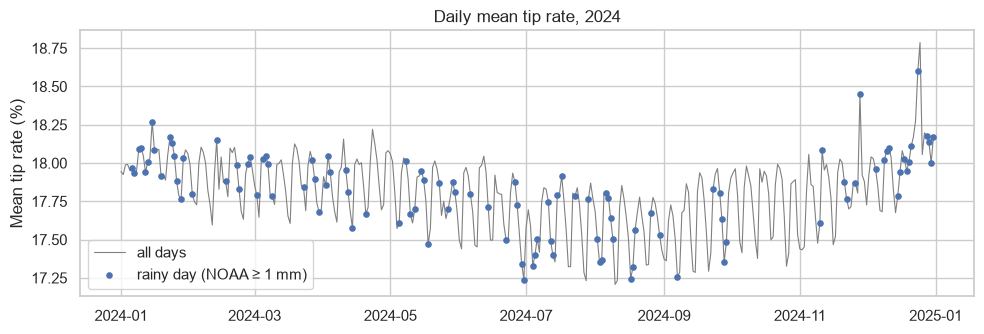

In [8]:
power = TTestIndPower()
n_rain, n_dry = daily.rainy.sum(), (~daily.rainy).sum()
mde_pilot = power.solve_power(nobs1=15, ratio=1, alpha=0.05, power=0.8)
mde_year = power.solve_power(nobs1=n_rain, ratio=n_dry / n_rain, alpha=0.05, power=0.8)
print(f"Minimum detectable effect (80% power): pilot 15 vs 15 days d = {mde_pilot:.2f}; "
      f"full year {n_rain} vs {n_dry} days d = {mde_year:.2f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily.date, daily.mean_tip_pct, color="grey", lw=0.8, label="all days")
ax.scatter(daily.date[daily.rainy], daily.mean_tip_pct[daily.rainy], color="#4C72B0", s=14,
           label="rainy day (NOAA ≥ 1 mm)", zorder=3)
ax.set(ylabel="Mean tip rate (%)", title="Daily mean tip rate, 2024")
ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(FIG + "02_daily_tip_timeseries.png", dpi=150); plt.show()

## 5. Are rainy days different in other ways? (confounding check)

If rain is more common in some months or weekdays, and tipping also differs across them, the simple comparison
above is confounded. A chi-square test checks whether rainy days are spread evenly across months and weekdays.

In [9]:
for col, names in [("month", None), ("dow", DOW)]:
    tab = pd.crosstab(daily[col], daily.rainy)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    share = (tab[True] / tab.sum(axis=1)).round(2)
    if names: share.index = names
    print(f"Share of rainy days by {col}: {share.to_dict()}")
    print(f"  chi-square = {chi2:.1f}, dof = {dof}, p = {p:.3f}\n")

Share of rainy days by month: {1: 0.48, 2: 0.24, 3: 0.29, 4: 0.23, 5: 0.35, 6: 0.23, 7: 0.32, 8: 0.39, 9: 0.2, 10: 0.0, 11: 0.2, 12: 0.48}
  chi-square = 30.0, dof = 11, p = 0.002

Share of rainy days by dow: {'Mon': 0.23, 'Tue': 0.25, 'Wed': 0.27, 'Thu': 0.37, 'Fri': 0.31, 'Sat': 0.37, 'Sun': 0.23}
  chi-square = 5.5, dof = 6, p = 0.479



### Day-level regression

$$\overline{\text{tip\_pct}}_d = \beta_0 + \beta_1\,\text{rainy}_d + \gamma_{\text{dow}(d)} + \delta_{\text{month}(d)}
+ \theta\,\text{holiday}_d + \lambda\,\text{temp}_d + \varepsilon_d$$

with heteroskedasticity-robust (HC3) standard errors. A second model adds the day's **trip mix** (mean log
distance and duration): if rain changes *which* trips people take (e.g. more short hops), the day-level average
can move even if no individual passenger tips differently.

In [10]:
coef_table = lambda m, names: pd.DataFrame({"coef": m.params[names], "std err": m.bse[names],
                                            "p": m.pvalues[names], "CI low": m.conf_int().loc[names, 0],
                                            "CI high": m.conf_int().loc[names, 1]}).round(3)
DAY_CONTROLS = "rainy + C(dow) + C(month) + holiday + era5_temp_c"
MIX = " + np.log(mean_distance) + np.log(mean_duration)"
day_models = {
    "tip rate, calendar controls": smf.ols("mean_tip_pct ~ " + DAY_CONTROLS, data=daily),
    "tip rate, + trip mix": smf.ols("mean_tip_pct ~ " + DAY_CONTROLS + MIX, data=daily),
    "tip $, calendar controls": smf.ols("mean_tip ~ " + DAY_CONTROLS, data=daily),
    "tip $, + trip mix": smf.ols("mean_tip ~ " + DAY_CONTROLS + MIX, data=daily),
}
pd.concat({k: coef_table(m.fit(cov_type="HC3"), ["rainy[T.True]"]) for k, m in day_models.items()}).droplevel(1)

,coef,std err,p,CI low,CI high
"tip rate, calendar controls",0.015,0.016,0.353,-0.016,0.045
"tip rate, + trip mix",0.008,0.015,0.603,-0.022,0.038
"tip $, calendar controls",-0.045,0.017,0.009,-0.079,-0.011
"tip $, + trip mix",0.003,0.005,0.518,-0.006,0.012


## 6. Trip-level regression: rain at the pickup hour

A day labelled "rainy" may have rain for only an hour or two, so the day-level test dilutes any effect. Here each
trip is matched to the precipitation **in its pickup hour** (ERA5). An hour counts as rainy if precipitation is
**≥ 0.25 mm** (0.01 inch, the standard threshold for "measurable" precipitation).

$$\text{tip\_pct}_i = \beta_0 + \beta_1\,\text{rain\_hour}_i + \alpha_{\text{hour}} + \gamma_{\text{dow}} +
\delta_{\text{month}} + \theta\,\text{holiday} + \lambda\,\text{temp} + \mathbf{x}_i'\boldsymbol{\eta} + \varepsilon_i$$

where $\mathbf{x}_i$ contains log distance, log duration, airport trip, JFK flat fare and passenger count.

**Standard errors are clustered by day.** Trips on the same day share the same weather and many unobserved
shocks (events, traffic), so treating ~30M trips as independent would make the standard errors far too small.
Clustering by day gives 366 effective clusters.

For speed the model is fit on a random sample of 3 million trips; section 7 shows the estimate is stable.

In [11]:
trips["rain_hour"] = trips.precip_mm >= 0.25
trips["log_distance"] = np.log(trips.distance_mi)
trips["log_duration"] = np.log(trips.duration_min)
trips["day_id"] = trips.date.dt.day_of_year
trips["tipped01"] = trips.tipped.astype("int8")  # numeric outcomes for the linear probability models
trips["tip_20_01"] = trips.tip_20.astype("int8")
reg = trips.dropna(subset=["precip_mm"]).sample(n=3_000_000, random_state=SEED)
print(f"Share of trips that start in a rainy hour: {reg.rain_hour.mean():.1%}")

CONTROLS = ("C(hour) + C(dow) + C(month) + holiday + temp_c + log_distance + log_duration"
            " + airport + jfk_flat_fare + passengers")

def fit(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["day_id"]})

m_raw = fit("tip_pct ~ rain_hour", reg)
m_full = fit("tip_pct ~ rain_hour + " + CONTROLS, reg)
m_tipped = fit("tipped01 ~ rain_hour + " + CONTROLS, reg)                       # extensive margin (LPM)
m_cond = fit("tip_pct ~ rain_hour + " + CONTROLS, reg[reg.tipped])            # intensive margin
m_default = fit("tip_20_01 ~ rain_hour + " + CONTROLS, reg)                   # chooses the 20% default
main = pd.concat({
    "tip_pct, no controls": coef_table(m_raw, ["rain_hour[T.True]"]),
    "tip_pct, full controls": coef_table(m_full, ["rain_hour[T.True]"]),
    "P(tip > 0), full controls": coef_table(m_tipped, ["rain_hour[T.True]"]),
    "tip_pct | tipped, full controls": coef_table(m_cond, ["rain_hour[T.True]"]),
    "P(tip = exactly 20%), full controls": coef_table(m_default, ["rain_hour[T.True]"]),
}).droplevel(1)
main["N"] = [int(m.nobs) for m in (m_raw, m_full, m_tipped, m_cond, m_default)]
main

Share of trips that start in a rainy hour: 9.0%


,coef,std err,p,CI low,CI high,N
"tip_pct, no controls",0.090,0.030,0.003,0.031,0.150,3000000
"tip_pct, full controls",0.017,0.018,0.343,-0.018,0.051,3000000
"P(tip > 0), full controls",-0.001,0.001,0.029,-0.002,-0.000,3000000
"tip_pct | tipped, full controls",0.039,0.017,0.023,0.005,0.073,2876571
"P(tip = exactly 20%), full controls",-0.005,0.001,0.000,-0.007,-0.002,3000000


In [12]:
print(f"Mean tip rate = {reg.tip_pct.mean():.2f}%, share tipped = {reg.tipped.mean():.3f}, "
      f"share at exactly 20% = {reg.tip_20.mean():.3f}")
b, lo, hi = m_full.params["rain_hour[T.True]"], *m_full.conf_int().loc["rain_hour[T.True]"]
print(f"Rain at pickup changes the tip by {b:+.3f} percentage points (95% CI {lo:+.3f} to {hi:+.3f}), "
      f"i.e. {100 * b / reg.tip_pct.mean():+.1f}% of the average tip rate.")
print(f"R-squared (full model): {m_full.rsquared:.3f}")

Mean tip rate = 17.81%, share tipped = 0.959, share at exactly 20% = 0.464
Rain at pickup changes the tip by +0.017 percentage points (95% CI -0.018 to +0.051), i.e. +0.1% of the average tip rate.
R-squared (full model): 0.007


## 7. Robustness checks

The main estimate should not depend on arbitrary choices. Each row below re-fits the full-controls model with one
change: a different rain threshold, a continuous intensity measure, the station-based daily rain definition, a
different outcome, a sample excluding airport trips, or a different random sample.

In [13]:
checks = []
def add(label, model, term):
    ci = model.conf_int().loc[term]
    checks.append({"specification": label, "coef": model.params[term], "CI low": ci[0], "CI high": ci[1],
                   "p": model.pvalues[term], "N": int(model.nobs)})

add("Main: rain hour >= 0.25 mm", m_full, "rain_hour[T.True]")
for thr in (0.1, 1.0, 2.5):
    reg["rain_thr"] = reg.precip_mm >= thr
    add(f"Rain hour >= {thr} mm", fit("tip_pct ~ rain_thr + " + CONTROLS, reg), "rain_thr[T.True]")
add("Intensity: per mm/h (continuous)", fit("tip_pct ~ precip_mm + " + CONTROLS, reg), "precip_mm")
reg["noaa_rainy_day"] = reg.noaa_prcp_mm >= 1
add("Daily NOAA rainy day (>= 1 mm)", fit("tip_pct ~ noaa_rainy_day + " + CONTROLS, reg),
    "noaa_rainy_day[T.True]")
add("Outcome: tip in $", fit("tip ~ rain_hour + " + CONTROLS, reg), "rain_hour[T.True]")
add("Outcome: tip as % of fare only", fit("tip_pct_fare ~ rain_hour + " + CONTROLS, reg), "rain_hour[T.True]")
no_air = reg[~reg.airport]
add("Excluding airport trips", fit("tip_pct ~ rain_hour + " + CONTROLS.replace(" + airport + jfk_flat_fare", ""),
                                   no_air), "rain_hour[T.True]")
reg2 = trips.dropna(subset=["precip_mm"]).sample(n=3_000_000, random_state=SEED + 1)
add("Different random sample", fit("tip_pct ~ rain_hour + " + CONTROLS, reg2), "rain_hour[T.True]")
robust = pd.DataFrame(checks).round(4)
robust

,specification,coef,CI low,CI high,p,N
0,Main: rain hour >= 0.25 mm,0.0167,-0.0177,0.0511,0.3427,3000000
1,Rain hour >= 0.1 mm,0.0037,-0.0230,0.0305,0.7855,3000000
2,Rain hour >= 1.0 mm,0.0237,-0.0271,0.0745,0.3600,3000000
3,Rain hour >= 2.5 mm,0.0287,-0.0508,0.1082,0.4789,3000000
4,Intensity: per mm/h (continuous),0.0032,-0.0100,0.0164,0.6353,3000000
5,Daily NOAA rainy day (>= 1 mm),0.0043,-0.0221,0.0306,0.7509,3000000
6,Outcome: tip in $,0.0228,0.0060,0.0397,0.0078,3000000
7,Outcome: tip as % of fare only,0.0506,-0.0231,0.1243,0.1786,3000000
8,Excluding airport trips,0.0066,-0.0301,0.0433,0.7249,2697121
9,Different random sample,0.0251,-0.0155,0.0658,0.2260,3000000


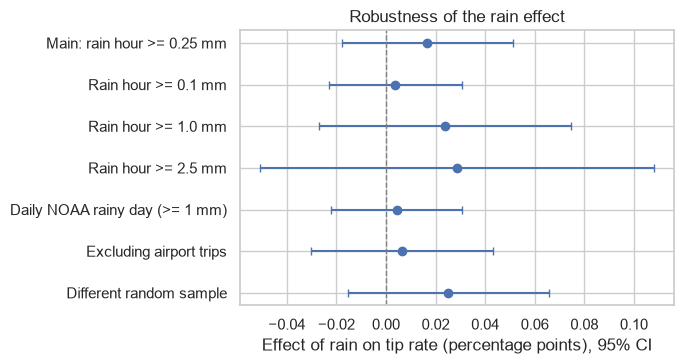

In [14]:
pp = robust[robust.specification.str.match("Main|Rain hour|Daily|Excluding|Different")]
fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(pp))[::-1]
ax.errorbar(pp.coef, y, xerr=[pp.coef - pp["CI low"], pp["CI high"] - pp.coef], fmt="o", capsize=3,
            color="#4C72B0")
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(y, pp.specification)
ax.set(xlabel="Effect of rain on tip rate (percentage points), 95% CI",
       title="Robustness of the rain effect")
plt.tight_layout(); plt.savefig(FIG + "02_robustness.png", dpi=150); plt.show()

## 8. Conclusion

**Main result: rain has no meaningful effect on how much passengers tip.** With rain measured at the pickup hour
and controls for time, trip characteristics and temperature, a rainy hour changes the tip rate by
**+0.02 percentage points (95% CI −0.02 to +0.05)** on a mean of 17.8%. The interval rules out any effect larger
than about 0.05 pp, i.e. 0.3% of the average tip rate. This is a *precisely estimated null*, not just a failure
to reject: unlike the 30-day pilot, the full-year analysis has the power to detect small effects. The null holds
across every robustness check (rain thresholds from 0.1 to 2.5 mm/h, continuous intensity, station-based daily
rain, excluding airport trips, a second random sample).

**Confounding matters.** Without controls, rainy hours show a small but significant *higher* tip rate
(+0.09 pp, p = 0.003). It disappears once hour, weekday and month are controlled for, because rain is unevenly
spread across the calendar (χ² test across months, p = 0.002) and tipping varies with time of day.

**The dollar gap on rainy days is a composition effect.** Rainy days have lower mean dollar tips
(−\$0.08, Welch p = 0.002, and −\$0.045 after calendar controls). Adding the day's mean trip distance and duration
removes the gap entirely (+\$0.003, p = 0.52): on rainy days people take shorter trips, which carry smaller dollar
tips, but they do not tip a smaller *share*.

**Why so little response? Defaults.** 46% of all card trips (56% of tippers) tip *exactly* 20% of the pre-tip
total, the preset button on the payment screen. Rain nudges this only marginally: in a rainy hour the probability
of choosing exactly 20% falls by 0.5 pp (p < 0.001, on a base of 46%) and the tip rate among tippers rises by
0.04 pp (p = 0.02). These are statistically detectable only because of the very large sample; in practical terms
they are negligible, which illustrates the difference between statistical and practical significance.

**Limitations.**
- Only card trips are observed; cash tips are not recorded, and passengers who pay cash may differ.
- Rain comes from a single grid point (Central Park). Local rain elsewhere in the city may differ, which adds
  measurement error and can bias the estimate towards zero, although the station check (r = 0.83) is reassuring.
- The design is observational. Controls remove the obvious confounders, but rain could still correlate with
  unobserved factors (e.g. events cancelled on rainy days).
- Several outcomes and specifications are tested; small p-values on secondary outcomes should be read with
  multiple comparisons in mind.